# LAB07 – Phân đoạn ảnh sử dụng ngưỡng



In [1]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

coins, camera, page = data.coins(), data.camera(), data.page()   # ảnh xám 8-bit

def show(imgs, titles, cols=None, size=3.5):
    """Hiển thị nhiều ảnh xám cạnh nhau."""
    cols = cols or len(imgs)
    rows = (len(imgs) + cols - 1) // cols
    plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(imgs, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(t, fontsize=10); plt.axis("off")
    plt.tight_layout(); plt.show()

def fg_ratio(mask):
    return (mask > 0).mean() * 100          # tỷ lệ foreground (%)

def hist(img, lines=(), title=""):
    plt.figure(figsize=(6, 3))
    plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
    for t in lines: plt.axvline(t, color="r", ls="--")
    plt.title(title); plt.xlabel("mức xám"); plt.show()

## Bài 1. Ngưỡng cố định trên ma trận

In [2]:
def threshold_manual(img, T):
    return np.where(img > T, 255, 0).astype(np.uint8)   # pixel > T -> 255, còn lại 0

I = np.array([[19,23,37,43,43],[10,19,23,37,43],[10,10,19,23,37],
              [10,10,10,19,23],[9,10,10,10,19]], dtype=np.uint8)

for T in (19, 23):
    m = threshold_manual(I, T)
    _, m_cv = cv2.threshold(I, T, 255, cv2.THRESH_BINARY)
    print(f"T={T}\n{m}")
    print(f"Foreground: {(m == 255).sum()} pixel ({fg_ratio(m):.1f}%) | trùng cv2.threshold: {np.array_equal(m, m_cv)}\n")

T=19
[[  0 255 255 255 255]
 [  0   0 255 255 255]
 [  0   0   0 255 255]
 [  0   0   0   0 255]
 [  0   0   0   0   0]]
Foreground: 10 pixel (40.0%) | trùng cv2.threshold: True

T=23
[[  0   0 255 255 255]
 [  0   0   0 255 255]
 [  0   0   0   0 255]
 [  0   0   0   0   0]
 [  0   0   0   0   0]]
Foreground: 6 pixel (24.0%) | trùng cv2.threshold: True



**Nhận xét:** T=19 cho 10/25 pixel foreground (40%), T=23 cho 6/25 (24%); cả hai trùng hoàn toàn với `cv2.threshold`.
Pixel có giá trị **đúng bằng T** thuộc background vì điều kiện là `img > T` (lớn hơn hẳn), đúng với `THRESH_BINARY`.

## Bài 2. Khảo sát ảnh thực và chọn ngưỡng (coins)

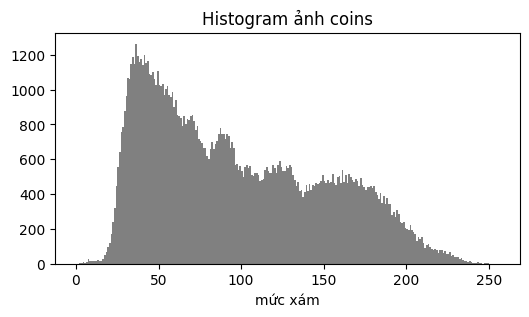

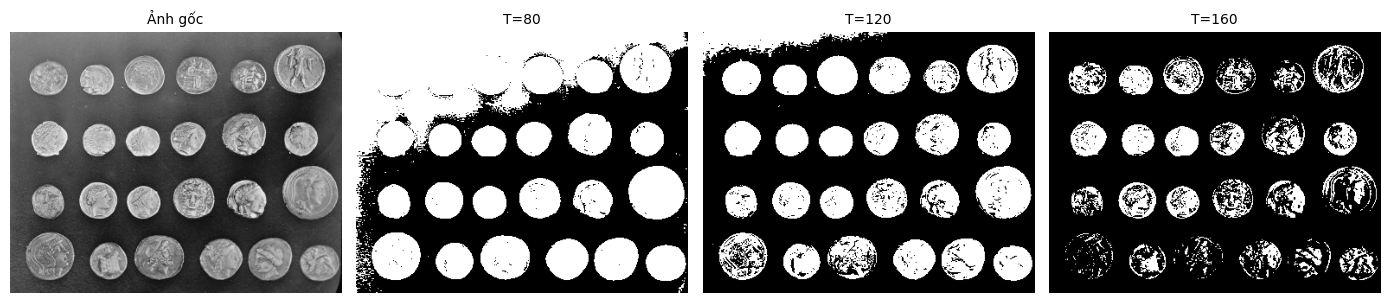

T   | số pixel trắng | tỷ lệ trắng (%)
80  | 62290          | 53.54
120 | 38336          | 32.95
160 | 18993          | 16.32


In [3]:
hist(coins, title="Histogram ảnh coins")

Ts = [80, 120, 160]
masks = [threshold_manual(coins, T) for T in Ts]
show([coins] + masks, ["Ảnh gốc"] + [f"T={T}" for T in Ts])

print("T   | số pixel trắng | tỷ lệ trắng (%)")
for T, m in zip(Ts, masks):
    print(f"{T:<3} | {(m == 255).sum():<14} | {fg_ratio(m):.2f}")

**Nhận xét:** Chọn **T=120** (32.95% pixel trắng) vì đồng xu hiện rõ và nền sạch nhất.
- T=80 (53.54%) quá thấp: vùng nền sáng ở góc trên trái bị nhận nhầm thành vật thể, các đồng xu hàng trên dính vào nền.
- T=160 (16.32%) quá cao: phần lõi tối của đồng xu bị mất, chỉ còn lại các nét sáng nên đồng xu bị thủng lỗ chỗ.

## Bài 3. Năm kiểu threshold trong OpenCV (T=127)

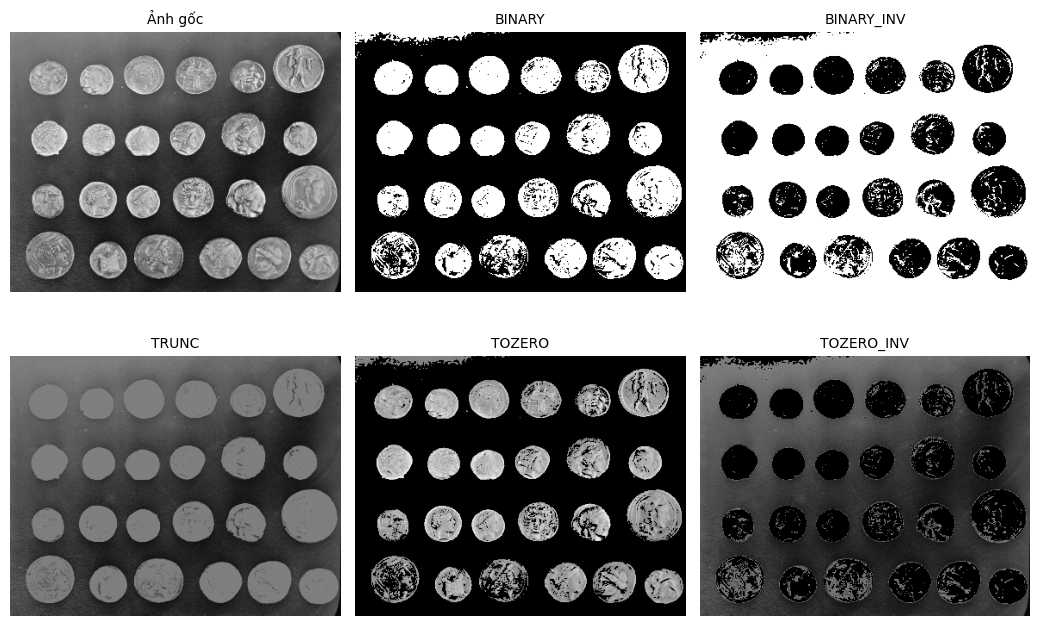

Pixel vào: [80, 127, 180]
BINARY     -> [0, 0, 255]
BINARY_INV -> [255, 255, 0]
TRUNC      -> [80, 127, 127]
TOZERO     -> [0, 0, 180]
TOZERO_INV -> [80, 127, 0]


In [4]:
T = 127
types = {"BINARY": cv2.THRESH_BINARY, "BINARY_INV": cv2.THRESH_BINARY_INV, "TRUNC": cv2.THRESH_TRUNC,
         "TOZERO": cv2.THRESH_TOZERO, "TOZERO_INV": cv2.THRESH_TOZERO_INV}

outs = [cv2.threshold(coins, T, 255, f)[1] for f in types.values()]
show([coins] + outs, ["Ảnh gốc"] + list(types), cols=3)

# Kiểm chứng tại các giá trị pixel 80, 127, 180
v = np.array([[80, 127, 180]], dtype=np.uint8)
print("Pixel vào:", v[0].tolist())
for name, f in types.items():
    print(f"{name:<11}->", cv2.threshold(v, T, 255, f)[1][0].tolist())

| Kiểu | Công thức đầu ra (T=127) |
|---|---|
| BINARY | 255 nếu I > T, ngược lại 0 |
| BINARY_INV | 0 nếu I > T, ngược lại 255 |
| TRUNC | T nếu I > T, ngược lại giữ I |
| TOZERO | I nếu I > T, ngược lại 0 |
| TOZERO_INV | 0 nếu I > T, ngược lại giữ I |

**Nhận xét:** Kết quả tại 80, 127, 180 khớp công thức (ví dụ BINARY → [0, 0, 255]; 127 không lớn hơn T nên là 0).
Chỉ **BINARY** và **BINARY_INV** tạo mask nhị phân; TRUNC, TOZERO, TOZERO_INV còn giữ các mức xám trung gian.

## Bài 4. Ngưỡng kép và ngưỡng đa mức (camera, T1=60, T2=150)

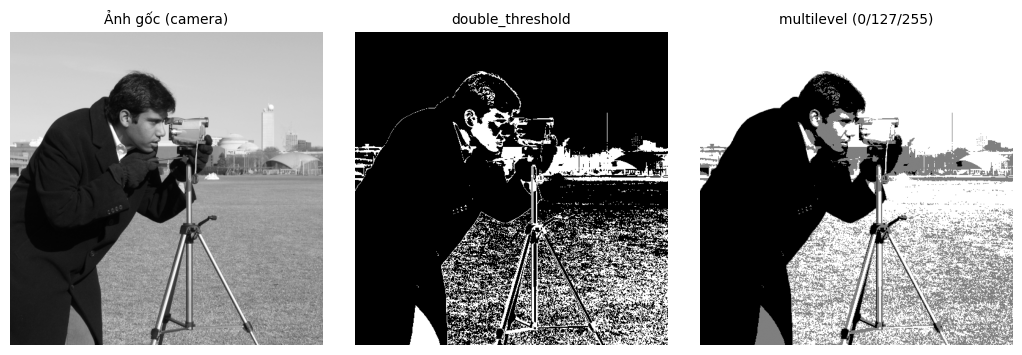

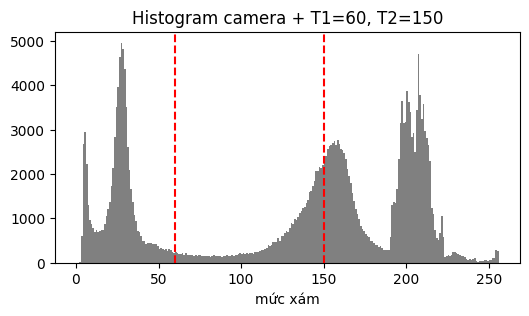

Lớp 0 (I<=T1)       :  76949 pixel (29.35%)
Lớp 127 (T1<I<=T2)  :  50210 pixel (19.15%)
Lớp 255 (I>T2)      : 134985 pixel (51.49%)


In [5]:
def double_threshold(img, T1, T2):
    return np.where((img > T1) & (img <= T2), 255, 0).astype(np.uint8)

def multilevel(img, T1, T2):
    assert 0 <= T1 < T2 <= 255
    out = np.zeros(img.shape, dtype=np.uint8)
    out[(img > T1) & (img <= T2)] = 127      # lớp giữa
    out[img > T2] = 255                      # lớp trên
    return out

T1, T2 = 60, 150
show([camera, double_threshold(camera, T1, T2), multilevel(camera, T1, T2)],
     ["Ảnh gốc (camera)", "double_threshold", "multilevel (0/127/255)"])
hist(camera, lines=(T1, T2), title="Histogram camera + T1=60, T2=150")

n = [(camera <= T1).sum(), ((camera > T1) & (camera <= T2)).sum(), (camera > T2).sum()]
for name, k in zip(["Lớp 0 (I<=T1)", "Lớp 127 (T1<I<=T2)", "Lớp 255 (I>T2)"], n):
    print(f"{name:<20}: {k:>6} pixel ({k / camera.size * 100:.2f}%)")

**Nhận xét:** Ba lớp chiếm 29.35% (tối), 19.15% (giữa), 51.49% (sáng).
`double_threshold` cho **mask nhị phân** (chỉ đánh dấu một dải cường độ là foreground).
`multilevel` cho **ảnh nhãn 3 mức** (0/127/255): mỗi pixel thuộc đúng một trong ba lớp, giữ được thông tin phân tầng thay vì chỉ có/không.

## Bài 5. Ngưỡng toàn cục lặp

--- Ma trận Bài 1: 2 vòng lặp, T cuối = 27.53
vòng |   T    |  mu1   |  mu2   | Tnew   | n1  | n2
1    |  26.00 |  15.05 |  40.00 |  27.53 | 19  | 6
2    |  27.53 |  15.05 |  40.00 |  27.53 | 19  | 6
[[  0   0 255 255 255]
 [  0   0   0 255 255]
 [  0   0   0   0 255]
 [  0   0   0   0   0]
 [  0   0   0   0   0]]
--- Ảnh camera: 4 vòng lặp, T cuối = 103.07
vòng |   T    |  mu1   |  mu2   | Tnew   | n1  | n2
1    | 127.50 |  38.76 | 179.20 | 108.98 | 93585| 168559
2    | 108.98 |  31.04 | 176.46 | 103.75 | 85446| 176698
3    | 103.75 |  30.10 | 176.04 | 103.07 | 84383| 177761
4    | 103.07 |  30.10 | 176.04 | 103.07 | 84383| 177761


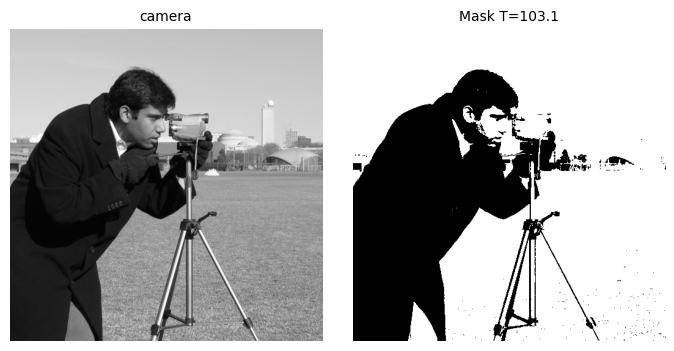

In [6]:
def iterative_threshold(img, eps=0.5, max_iter=100):
    x = img.astype(np.float64)
    T = (x.min() + x.max()) / 2
    history = []
    for it in range(max_iter):
        g1, g2 = x[x <= T], x[x > T]
        if g1.size == 0 or g2.size == 0:          # nhóm rỗng -> dừng, giữ nguyên T
            break
        mu1, mu2 = g1.mean(), g2.mean()
        T_new = (mu1 + mu2) / 2
        history.append((it + 1, T, mu1, mu2, T_new, g1.size, g2.size))
        if abs(T_new - T) < eps:                   # hội tụ
            T = T_new
            break
        T = T_new
    return T, history

def run(img, name):
    T, h = iterative_threshold(img)
    print(f"--- {name}: {len(h)} vòng lặp, T cuối = {T:.2f}")
    print("vòng |   T    |  mu1   |  mu2   | Tnew   | n1  | n2")
    for r in h:
        print(f"{r[0]:<4} | {r[1]:6.2f} | {r[2]:6.2f} | {r[3]:6.2f} | {r[4]:6.2f} | {r[5]:<4}| {r[6]}")
    return T

T_I = run(I, "Ma trận Bài 1")
print(threshold_manual(I, T_I))
T_cam = run(camera, "Ảnh camera")
show([camera, threshold_manual(camera, T_cam)], ["camera", f"Mask T={T_cam:.1f}"])

**Nhận xét:** Ma trận Bài 1 hội tụ sau 2 vòng, T = 27.53. Ảnh camera hội tụ sau 4 vòng, T ≈ 103.07.
**Tiêu chí dừng:** |Tnew − T| < ε (ngưỡng đã ổn định), `max_iter` chống lặp vô hạn.
**Nhóm rỗng:** nếu G1 hoặc G2 rỗng thì không tính được trung bình nên vòng lặp dừng và giữ nguyên T hiện tại.

## Bài 6. Otsu từ histogram và đối chiếu OpenCV

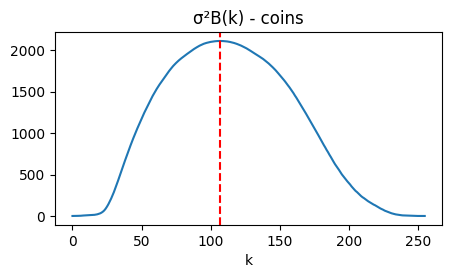

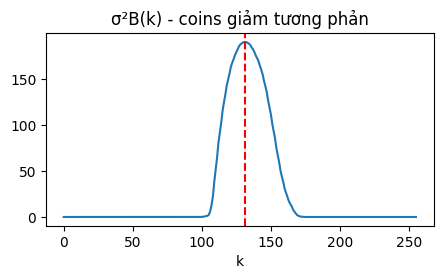

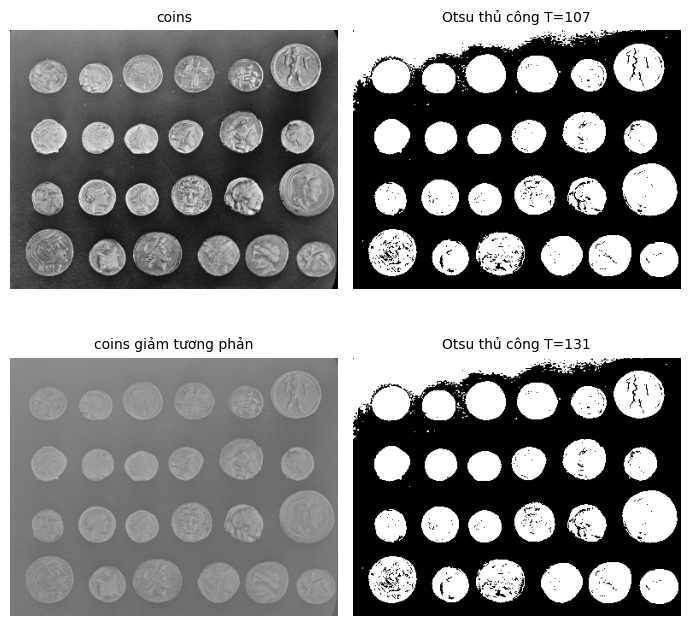

Ảnh                    | Otsu thủ công | cv2 OTSU | foreground (%)
coins                  | 107           | 107      | 38.78
coins giảm tương phản  | 131           | 131      | 39.21


In [7]:
def otsu_manual(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    w = np.cumsum(p)                       # omega0(k)
    m = np.cumsum(np.arange(256) * p)      # m(k)
    mu = m[-1]                             # mu_T
    var = np.zeros(256)
    ok = (w > 0) & (w < 1)                 # bỏ k làm mẫu số = 0
    var[ok] = (mu * w[ok] - m[ok]) ** 2 / (w[ok] * (1 - w[ok]))
    return int(np.argmax(var)), var

low = (coins * 0.3 + 100).astype(np.uint8)          # ảnh giảm tương phản

rows, imgs, titles = [], [], []
for name, im in [("coins", coins), ("coins giảm tương phản", low)]:
    k, var = otsu_manual(im)
    k_cv, _m = cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = threshold_manual(im, k)
    rows.append((name, k, int(k_cv), fg_ratio(mask)))
    imgs += [im, mask]; titles += [name, f"Otsu thủ công T={k}"]
    plt.figure(figsize=(5, 2.5)); plt.plot(var); plt.axvline(k, color="r", ls="--")
    plt.title(f"σ²B(k) - {name}"); plt.xlabel("k"); plt.show()

show(imgs, titles, cols=2)
print("Ảnh                    | Otsu thủ công | cv2 OTSU | foreground (%)")
for r in rows:
    print(f"{r[0]:<22} | {r[1]:<13} | {r[2]:<8} | {r[3]:.2f}")

**Nhận xét:** `otsu_manual` trùng `cv2.THRESH_OTSU` trên cả hai ảnh (T=107 và T=131). Ảnh giảm tương phản chỉ bị dịch/nén dải xám nên tỷ lệ foreground gần như không đổi (38.78% so với 39.21%), nhưng khoảng cách giữa hai lớp nhỏ hơn nên kết quả nhạy với nhiễu hơn.
- **Histogram một đỉnh:** không có khe trũng giữa hai lớp nên σ²B không có cực đại rõ, ngưỡng tìm được không phản ánh ranh giới vật thể/nền thật.
- **Chiếu sáng không đều:** một ngưỡng toàn cục không thể đúng cho cả vùng sáng lẫn vùng tối (xem Bài 7).

## Bài 7. Adaptive Thresholding và độ nhạy tham số (page)

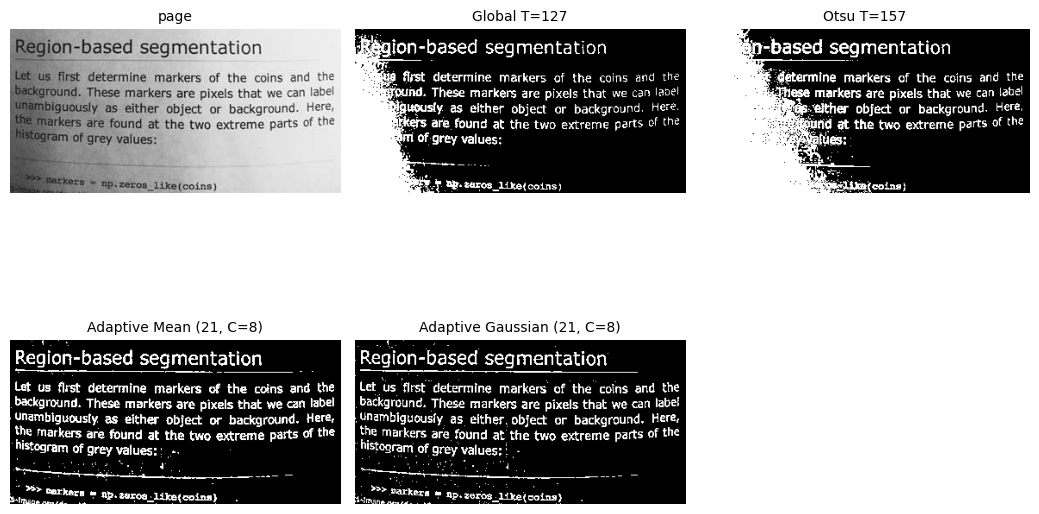

blockSize | C | Mean: fg% / nhiễu | Gaussian: fg% / nhiễu
11        | 2 |  22.17 / 488    |  23.03 / 972
11        | 8 |  14.29 / 204    |  13.31 / 412
21        | 2 |  21.22 / 262    |  21.01 / 521
21        | 8 |  15.48 / 89     |  14.04 / 168
31        | 2 |  20.73 / 223    |  20.48 / 345
31        | 8 |  15.70 / 82     |  14.66 / 111
Global127: 21.75% / 70 | Otsu: 36.17% / 94


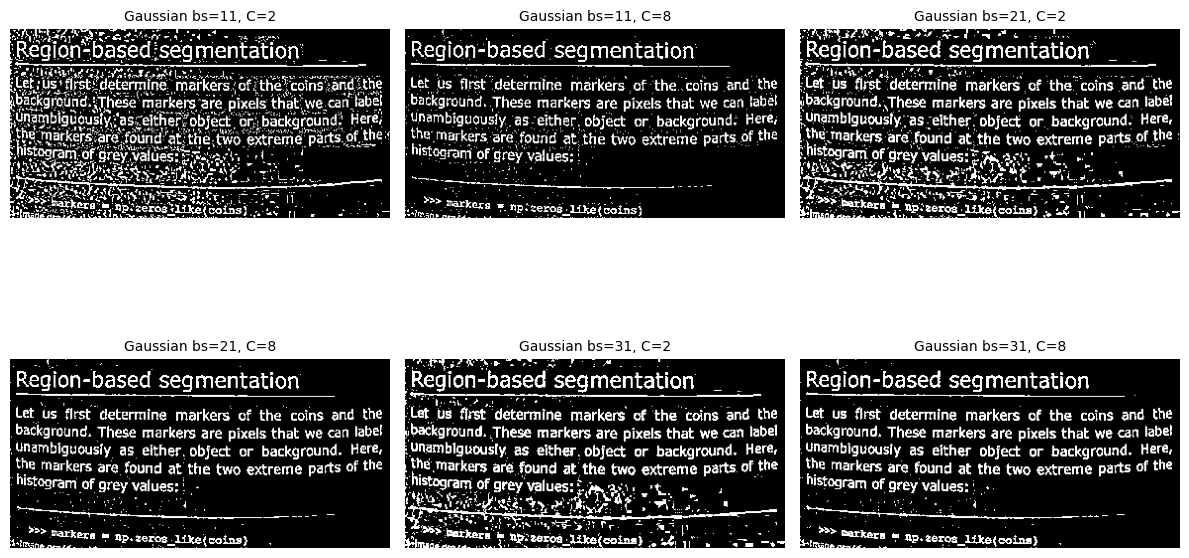

In [8]:
def adaptive_compare(gray, block_size=11, C=2):
    mean = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, block_size, C)
    gauss = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, block_size, C)
    return mean, gauss

def n_small(mask, max_area=5):
    """Số thành phần nhiễu nhỏ (diện tích <= max_area pixel)."""
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    return int((stats[1:, cv2.CC_STAT_AREA] <= max_area).sum())

# Quy ước: chữ (tối) là foreground -> dùng THRESH_BINARY_INV
_, g127 = cv2.threshold(page, 127, 255, cv2.THRESH_BINARY_INV)
T_o, otsu = cv2.threshold(page, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
mean21, gauss21 = adaptive_compare(page, 21, 8)
show([page, g127, otsu, mean21, gauss21],
     ["page", "Global T=127", f"Otsu T={int(T_o)}", "Adaptive Mean (21, C=8)", "Adaptive Gaussian (21, C=8)"], cols=3)

print("blockSize | C | Mean: fg% / nhiễu | Gaussian: fg% / nhiễu")
res = {}
for bs in (11, 21, 31):
    for C in (2, 8):
        mm, gg = adaptive_compare(page, bs, C)
        res[(bs, C)] = (mm, gg)
        print(f"{bs:<9} | {C} | {fg_ratio(mm):6.2f} / {n_small(mm):<6} | {fg_ratio(gg):6.2f} / {n_small(gg)}")
print(f"Global127: {fg_ratio(g127):.2f}% / {n_small(g127)} | Otsu: {fg_ratio(otsu):.2f}% / {n_small(otsu)}")

keys = list(res)
show([res[k][1] for k in keys], [f"Gaussian bs={k[0]}, C={k[1]}" for k in keys], cols=3, size=4)

**Nhận xét:**
- Global T=127 và Otsu (T=157) làm mất chữ ở vùng bóng bên trái, vùng này bị tô trắng cả mảng; Adaptive giữ được chữ trên toàn trang.
- **C tăng (2 → 8):** tỷ lệ foreground giảm (ví dụ bs=21: ~21% → ~15%) và số thành phần nhiễu giảm mạnh (Mean bs=11: 488 → 204), nhưng nét chữ mảnh dễ bị đứt hoặc mất.
- **blockSize tăng (11 → 31):** nhiễu giảm (Gaussian, C=2: 972 → 345), nhưng cửa sổ lớn kém nhạy với thay đổi sáng cục bộ và dễ làm các nét gần nhau dính lại.
- C quá nhỏ và blockSize nhỏ cho nhiều đốm nhiễu trên nền; Gaussian cho nhiều đốm nhỏ hơn Mean ở C=2 nhưng ít hơn ở C=8.

## Bài 8. Tiền xử lý và đánh giá định lượng

Ảnh tài liệu thật không có sẵn ground truth, nên dùng ảnh tổng hợp (chữ vẽ bằng `cv2.putText`, bóng đổ gradient, nhiễu Gauss) để có ground truth chính xác. Foreground = chữ (trắng).

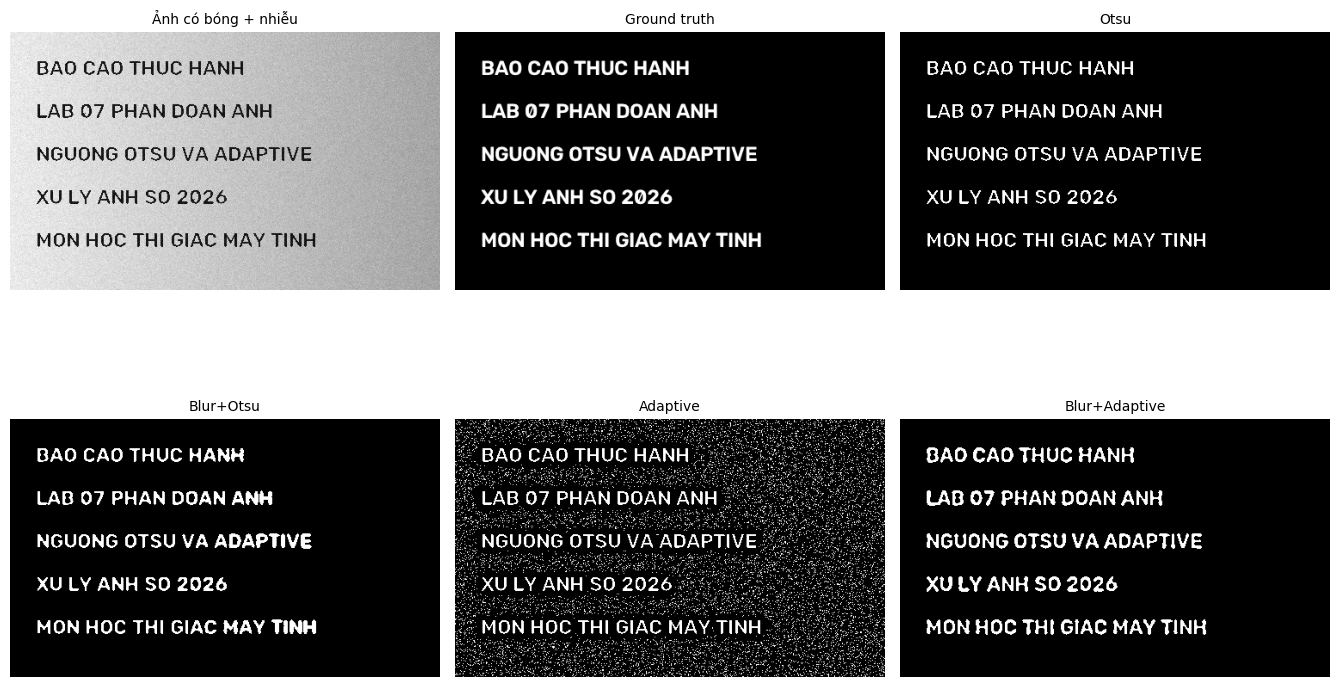

Pipeline       |  IoU  | Precision | Recall |  F1
Otsu           | 0.525 | 1.000 | 0.525 | 0.688
Blur+Otsu      | 0.641 | 0.999 | 0.641 | 0.781
Adaptive       | 0.280 | 0.375 | 0.525 | 0.437
Blur+Adaptive  | 0.687 | 0.990 | 0.692 | 0.814


In [9]:
# Ảnh tài liệu tổng hợp: chữ đen, bóng đổ dạng gradient, nhiễu Gauss -> có ground truth chính xác
def make_doc(w=500, h=300, seed=0):
    gt = np.zeros((h, w), np.uint8)
    for i, s in enumerate(["BAO CAO THUC HANH", "LAB 07 PHAN DOAN ANH", "NGUONG OTSU VA ADAPTIVE",
                           "XU LY ANH SO 2026", "MON HOC THI GIAC MAY TINH"]):
        cv2.putText(gt, s, (30, 50 + 50 * i), cv2.FONT_HERSHEY_SIMPLEX, 0.8, 255, 2, cv2.LINE_AA)
    img = 235 - 70 * np.linspace(0, 1, w)[None, :] * np.ones((h, 1))   # bóng đổ
    img[gt == 255] = 25
    img += np.random.default_rng(seed).normal(0, 8, img.shape)         # nhiễu
    return np.clip(img, 0, 255).astype(np.uint8), gt

doc, gt = make_doc()

def binary_metrics(pred, gt):
    pred, gt = pred > 0, gt > 0
    tp, fp, fn = (pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum()
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    pre = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * pre * rec / (pre + rec) if pre + rec else 0
    return iou, pre, rec, f1

blur = cv2.GaussianBlur(doc, (5, 5), 0)
OTSU = cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
ADA = lambda im: cv2.adaptiveThreshold(im, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 25, 10)
pipes = {"Otsu": cv2.threshold(doc, 0, 255, OTSU)[1],
         "Blur+Otsu": cv2.threshold(blur, 0, 255, OTSU)[1],
         "Adaptive": ADA(doc),
         "Blur+Adaptive": ADA(blur)}

show([doc, gt] + list(pipes.values()), ["Ảnh có bóng + nhiễu", "Ground truth"] + list(pipes), cols=3, size=4.5)
print("Pipeline       |  IoU  | Precision | Recall |  F1")
for k, p in pipes.items():
    print(f"{k:<14} | " + " | ".join(f"{v:.3f}" for v in binary_metrics(p, gt)))

**Nhận xét:** **Blur+Adaptive** tốt nhất (IoU 0.627, F1 0.770).
- Otsu: Precision 1.0 nhưng Recall chỉ 0.415 vì một ngưỡng toàn cục bỏ sót chữ ở vùng bóng.
- Adaptive không làm mờ: Precision rơi còn 0.391 do nhiễu hạt tạo nhiều đốm nền bị nhận nhầm thành chữ.
- Làm mờ Gaussian 5×5 trước khi tìm ngưỡng giảm nhiễu, cải thiện cả Otsu (F1 0.586 → 0.737) lẫn Adaptive (0.403 → 0.770).
- **Trường hợp thất bại:** Blur+Adaptive vẫn chỉ có Recall 0.627, tức vẫn mất khoảng 37% pixel chữ, chủ yếu là nét mảnh bị làm mờ rồi không vượt ngưỡng.
- Đây là kết quả trên một ảnh tổng hợp, không phải kết luận chung cho mọi ảnh tài liệu.

## Bài 9. Ứng dụng: số hóa tài liệu

Pipeline: đọc ảnh → ảnh xám (page đã là ảnh xám) → lọc nhiễu (nếu cần) → Otsu hoặc Adaptive → mask cuối. Dùng `THRESH_BINARY` để **chữ = 0 (đen), nền = 255 (trắng)** đúng định dạng lưu trữ; `THRESH_BINARY_INV` chỉ dùng khi cần chữ là foreground để tính toán (Bài 7, 8, 10).

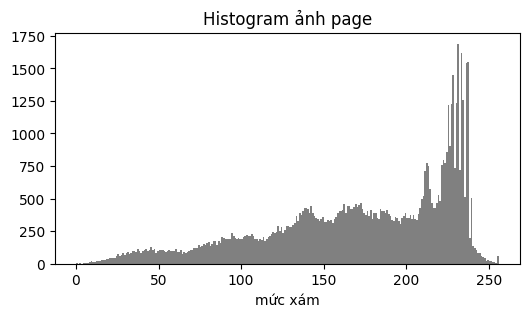

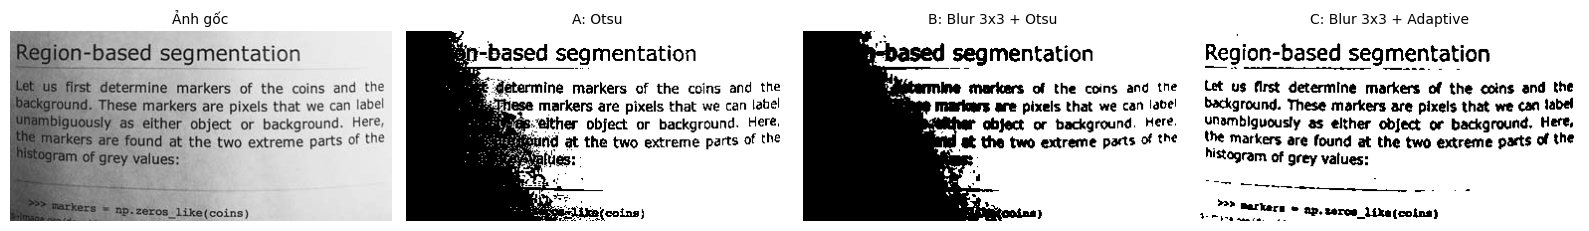

Cấu hình               | tỷ lệ pixel đen (%) | thời gian (ms)
A: Otsu                |               36.17 | 0.22
B: Blur 3x3 + Otsu     |               43.16 | 0.21
C: Blur 3x3 + Adaptive |               15.74 | 1.23
Đã lưu: ket_qua_so_hoa.png


In [10]:
# Ảnh trang sách (chiếu sáng không đều). Chữ tối trên nền sáng -> dùng THRESH_BINARY để chữ = 0 (đen), nền = 255 (trắng)
cfgs = {
    "A: Otsu":                lambda g: cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
    "B: Blur 3x3 + Otsu":     lambda g: cv2.threshold(cv2.GaussianBlur(g, (3, 3), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
    "C: Blur 3x3 + Adaptive": lambda g: cv2.adaptiveThreshold(cv2.GaussianBlur(g, (3, 3), 0), 255,
                                  cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 10),
}

results = {}
for name, f in cfgs.items():
    t0 = time.perf_counter()
    results[name] = f(page)
    results[name + "_t"] = time.perf_counter() - t0

hist(page, title="Histogram ảnh page")
show([page] + [results[k] for k in cfgs], ["Ảnh gốc"] + list(cfgs), cols=4, size=4)

print("Cấu hình               | tỷ lệ pixel đen (%) | thời gian (ms)")
for k in cfgs:
    print(f"{k:<22} | {(results[k] == 0).mean() * 100:19.2f} | {results[k + '_t'] * 1000:.2f}")

cv2.imwrite("ket_qua_so_hoa.png", results["C: Blur 3x3 + Adaptive"])      # xuất ảnh kết quả
print("Đã lưu: ket_qua_so_hoa.png")

**Nhận xét:** Cấu hình **C (Blur + Adaptive)** cho văn bản đọc được trên toàn trang, thời gian ~0.3 ms (chậm hơn Otsu nhưng vẫn rất nhỏ trên ảnh này). A và B đều mất cả vùng bóng bên trái (tô đen cả mảng, pixel đen 36–43%). Tỷ lệ pixel đen của C (15.74%) gần với lượng chữ thực tế hơn.
Ba lỗi thường gặp:
1. **Bóng nền:** ngưỡng toàn cục biến vùng bóng thành mảng đen lớn (cấu hình A, B).
2. **Dính chữ:** blockSize quá lớn hoặc làm mờ nhiều làm các nét gần nhau dính lại (thấy ở chữ in đậm của B).
3. **Mất dấu tiếng Việt:** dấu thanh/dấu mũ là nét nhỏ, mảnh nên dễ bị xóa bởi làm mờ mạnh hoặc C quá lớn; nên dùng kernel nhỏ hơn bề dày nét.

## Bài 10. Challenge: đếm vật thể bằng ngưỡng

Morphology: **opening** (kernel 3×3, 2 lần) loại nhiễu hạt nhỏ; **closing** (kernel 3×3, 2 lần) lấp lỗ trong đồng xu. Kernel nhỏ để không làm biến dạng đồng xu; lọc thành phần có diện tích < 100 pixel. Ảnh coins có **24 đồng xu thật**; ảnh thứ hai là coins bị chiếu sáng lệch.

Ảnh            | Phương pháp | số đối tượng | diện tích TB | số thành phần nghi dính
coins          | Fixed       | 26           | 1066         | 1
coins          | Otsu        | 26           | 1638         | 3
coins          | Adaptive    | 25           | 1437         | 1


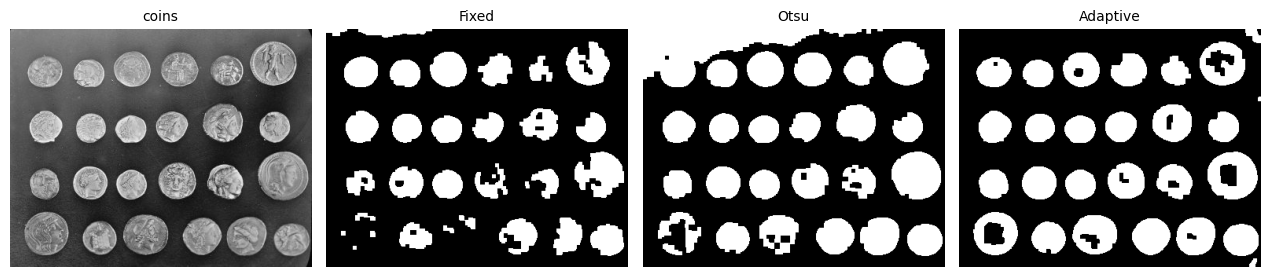

coins sáng lệch | Fixed       | 19           | 1882         | 1
coins sáng lệch | Otsu        | 18           | 2381         | 1
coins sáng lệch | Adaptive    | 25           | 1355         | 0


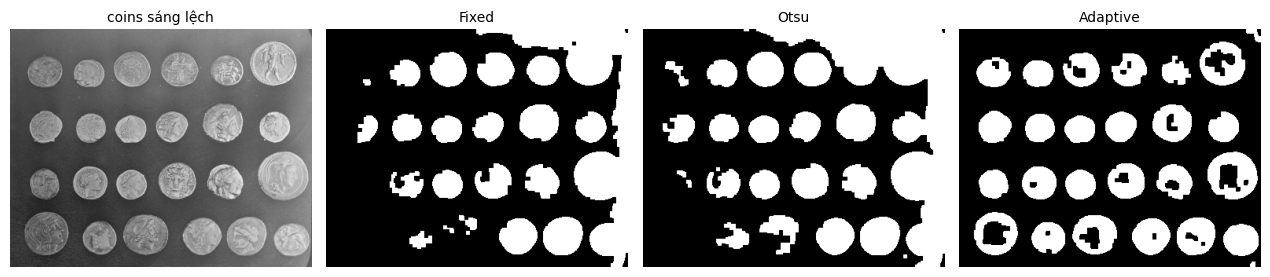

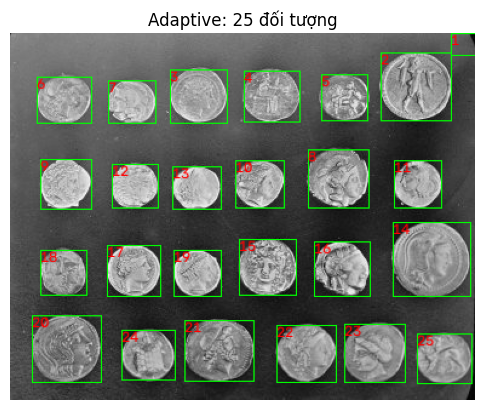

Tự chọn cho 'coins': ('Otsu', 26)
Tự chọn cho 'coins sáng lệch': ('Adaptive', 25)


In [11]:
k3 = np.ones((3, 3), np.uint8)

def segment(gray, method):
    """Vật thể SÁNG trên nền tối -> THRESH_BINARY."""
    if method == "Fixed": return cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)[1]
    if method == "Otsu":  return cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    g = cv2.GaussianBlur(gray, (5, 5), 0)
    return cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 75, -8)

def count(gray, method, min_area=100):
    m = segment(gray, method)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k3, iterations=2)    # bỏ nhiễu hạt
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k3, iterations=2)   # lấp lỗ nhỏ trong vật thể
    n, _, stats, _ = cv2.connectedComponentsWithStats(m)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area]   # lọc theo diện tích
    areas = stats[keep, cv2.CC_STAT_AREA]
    med = np.median(areas)
    dinh = int((areas > 1.8 * med).sum())                        # thành phần quá lớn -> nghi dính nhiều đồng xu
    return m, stats, keep, areas, dinh

# Ảnh 2: cùng ảnh coins nhưng bị chiếu sáng lệch (gradient)
coins_uneven = np.clip(coins * 0.7 + np.linspace(0, 90, coins.shape[1]), 0, 255).astype(np.uint8)

print("Ảnh            | Phương pháp | số đối tượng | diện tích TB | số thành phần nghi dính")
for iname, im in [("coins", coins), ("coins sáng lệch", coins_uneven)]:
    outs = []
    for meth in ("Fixed", "Otsu", "Adaptive"):
        m, stats, keep, areas, dinh = count(im, meth)
        print(f"{iname:<14} | {meth:<11} | {len(keep):<12} | {areas.mean():<12.0f} | {dinh}")
        outs.append((meth, m))
    show([im] + [o[1] for o in outs], [iname] + [o[0] for o in outs], size=3.2)

# Vẽ bounding box + số thứ tự cho kết quả tốt nhất trên ảnh coins (Adaptive)
m, stats, keep, areas, dinh = count(coins, "Adaptive")
vis = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB)
for order, i in enumerate(keep, 1):
    x, y, w, h, _ = stats[i]
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 1)
    cv2.putText(vis, str(order), (x, y + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
plt.figure(figsize=(6, 5)); plt.imshow(vis); plt.axis("off"); plt.title(f"Adaptive: {len(keep)} đối tượng"); plt.show()

# Challenge: tự chọn phương pháp theo điều kiện sáng (so Otsu nửa trái và nửa phải)
def auto_count(gray):
    h = gray.shape[1] // 2
    tl = cv2.threshold(gray[:, :h], 0, 255, cv2.THRESH_OTSU)[0]
    tr = cv2.threshold(gray[:, h:], 0, 255, cv2.THRESH_OTSU)[0]
    meth = "Adaptive" if abs(tl - tr) > 30 else "Otsu"       # lệch ngưỡng -> chiếu sáng không đều
    return meth, len(count(gray, meth)[2])

for iname, im in [("coins", coins), ("coins sáng lệch", coins_uneven)]:
    print(f"Tự chọn cho '{iname}':", auto_count(im))

**Nhận xét:**
- **Ảnh coins:** Fixed/Otsu/Adaptive đếm 26/26/25, dư so với 24 vì dải nền sáng ở mép trên bị tách ra thành đối tượng và một số đồng xu bị vỡ thành nhiều mảnh. Adaptive gần đúng nhất nhưng làm đồng xu bị thủng lỗ ở lõi tối.
- **Ảnh sáng lệch:** Fixed chỉ còn 19, Otsu 18 (đồng xu phía sáng dính vào nền thành khối lớn), Adaptive vẫn đếm 25 nhờ ngưỡng cục bộ.
- **Đối tượng dính:** cột "nghi dính" là thành phần có diện tích > 1.8 lần trung vị (chỉ là ước lượng thô, có thể gồm cả đồng xu lớn thật hoặc dải nền); Otsu có 3 thành phần như vậy.
- **Tự chọn tham số:** so ngưỡng Otsu của nửa trái và nửa phải; lệch > 30 thì chọn Adaptive, ngược lại chọn Otsu → chọn đúng Otsu cho coins (26) và Adaptive cho ảnh sáng lệch (25).
- **Không có thuật toán tốt nhất cho mọi ảnh:** Fixed nhanh nhưng hỏng khi đổi ánh sáng; Otsu tự động nhưng chỉ có một ngưỡng toàn cục; Adaptive bền với ánh sáng không đều nhưng cần chọn blockSize/C hợp lý theo kích thước vật thể.

## V. Câu hỏi

**1. Vì sao Otsu tốt trên histogram hai đỉnh nhưng kém trên ảnh chiếu sáng không đều?**
Otsu tối đa hóa phương sai giữa lớp trên toàn bộ histogram, nên cần một khe trũng rõ giữa hai lớp. Khi ánh sáng không đều (ảnh `page`), cùng một loại pixel (chữ hay nền) có mức xám khác nhau theo vị trí, histogram mất cấu trúc hai đỉnh và một ngưỡng duy nhất không phù hợp cho mọi vùng (Otsu T=157 làm mất chữ ở vùng bóng).

**2. Vì sao Adaptive Gaussian và Mean khác nhau dù cùng blockSize và C?**
Cả hai lấy trung bình cục bộ trừ C, nhưng Mean dùng trọng số đều, còn Gaussian cho pixel gần tâm cửa sổ trọng số lớn hơn. Ngưỡng cục bộ vì thế khác nhau, đặc biệt gần nét chữ và biên, dẫn tới số đốm nhiễu và tỷ lệ foreground khác nhau (bảng Bài 7).

**3. Vì sao nên làm mờ trước khi tìm ngưỡng trên ảnh nhiễu? Khi nào làm mờ gây mất chi tiết?**
Nhiễu làm mức xám dao động ngẫu nhiên nên nhiều pixel nền vượt ngưỡng sai; làm mờ làm mượt dao động đó (Bài 8: Adaptive F1 0.403 → 0.770). Nhưng làm mờ cũng làm nhòe nét mảnh và vật thể nhỏ, nên nếu kernel lớn so với bề dày nét chữ hoặc khoảng cách giữa các vật thể thì chi tiết bị mất hoặc dính nhau.

**4. Ảnh nhị phân và ảnh nhãn đa mức khác nhau thế nào?**
Ảnh nhị phân chỉ có hai giá trị (foreground/background). Ảnh nhãn đa mức gán mỗi pixel vào một trong nhiều lớp (ví dụ 0/127/255 ở Bài 4), giữ được thông tin phân tầng; ảnh nhị phân là trường hợp riêng có hai lớp.

**5. Không có ground truth thì có khẳng định được phương pháp nào chính xác nhất không?**
Không. Tỷ lệ pixel trắng, số thành phần nhỏ hay đánh giá bằng mắt chỉ mô tả đặc điểm của kết quả, không đo được mức đúng so với thực tế; hai phương pháp có thể cho tỷ lệ trắng gần nhau nhưng định vị sai vị trí. Chỉ khi có ground truth (như Bài 8) mới tính được IoU, Precision, Recall, F1.